## Clustering: Densidad 

- DBSCAN y HDBSCAN

- Grupos por densidad y se marcan **outliers** con **sklearn**

### Constantes

#### a. DBSCAN

- `RANGO_MS`: `min_samples`, vecinos para ser punto denso

- `RANGO_Q`: cuantiles de la k-distancia que se prueban como `eps`

- `RANGO_RUIDO`: % de ruido máximo aceptable para elegir la configuración

#### b. HDBSCAN

- `RANGO_MCS`: `min_cluster_size`, tamaño mínimo de un grupo

- `RANGO_MS_H`: `min_samples`, vecinos para ser punto denso

- `RANGO_SEL`: método de selección de grupos (`eom` o `leaf`)

- `RANGO_RUIDO_H`: % de ruido máximo aceptable para elegir la configuración

#### c. Costo

- `RANGO_N`: tamaños para medir tiempo y memoria

In [1]:
# DBSCAN
RANGO_MS = [5, 10, 20]
RANGO_Q = [0.80, 0.85, 0.90, 0.95, 0.98]
RANGO_RUIDO = [0.05, 0.10, 0.20]

# HDBSCAN
RANGO_MCS = [10, 25, 50, 100]
RANGO_MS_H = [1, 5, 10]
RANGO_SEL = ["eom", "leaf"]
RANGO_RUIDO_H = [0.20, 0.30, 0.40]

# costo
RANGO_N = [1000, 2000, 5000, 10000]

### Utilidades

In [2]:
NOTEBOOK = "c_densidad"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, HDBSCAN

config = leer_config()

def elegir(g, ruido_max):
    ok = g[(g.n_clusters >= 2) & (g.pct_ruido <= 100 * ruido_max)]
    return ok.sort_values("silueta", ascending=False).iloc[0] if len(ok) else None

### Carga

Mismo espacio que KMeans: los `n_comp` componentes del PCA

In [5]:
datos = {}
for s, c in config.items():
    d, X = cargar_local(s, c["n_comp"])
    d = d.merge(pd.read_parquet(datos_dir / f"kmeans_{s}"), on=c["key"])
    datos[s] = (d, X)
    print(f"{s}: {X.shape[0]:,} actores × {X.shape[1]} componentes")

entidad: 2,696 actores × 6 componentes
proveedor: 13,317 actores × 6 componentes


---
### **1. Gráfico de k-distancia**

Distancia de cada punto a su `min_samples`-ésimo vecino

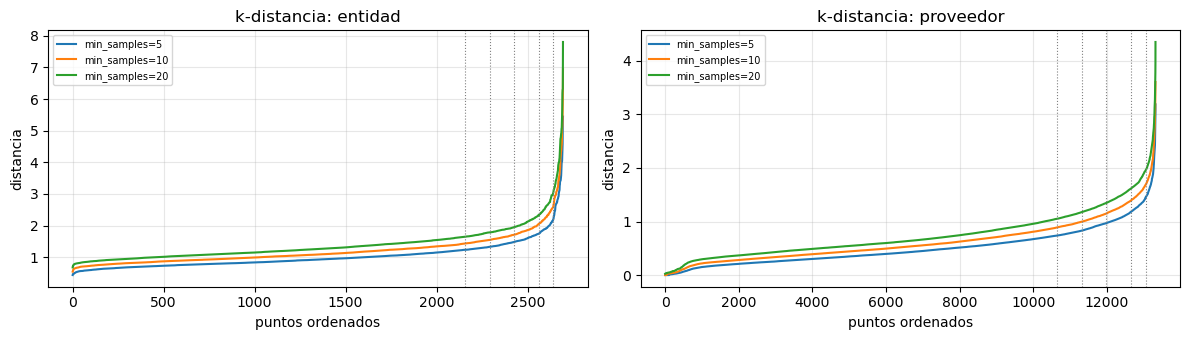

In [6]:
kdist = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, (s, (d, X)) in enumerate(datos.items()):
    for ms in RANGO_MS:
        kdist[(s, ms)] = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
        ax[i].plot(kdist[(s, ms)], label=f"min_samples={ms}")
    for q in RANGO_Q:
        ax[i].axvline(q * len(X), color="grey", ls=":", lw=.8)
    ax[i].set_title(f"k-distancia: {s}"); ax[i].set_xlabel("puntos ordenados"); ax[i].set_ylabel("distancia"); ax[i].legend(fontsize=7)
mostrar_fig("k_distancia")

---
### **2. DBSCAN: `eps` × `min_samples`**

In [7]:
grid_db, lab_db = [], {}
for s, (d, X) in datos.items():
    for ms in RANGO_MS:
        for q in RANGO_Q:
            eps = float(np.quantile(kdist[(s, ms)], q))
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            lab_db[(s, ms, q)] = lab
            grid_db.append({"sujeto": s, "min_samples": ms, "q_eps": q, "eps": round(eps, 3), "n_clusters": len(set(lab) - {-1}),
                            "pct_ruido": round(100 * (lab == -1).mean(), 1), "silueta": round(silueta(X, lab), 3)})
grid_db = pd.DataFrame(grid_db)
grid_db.pivot_table(index=["min_samples", "q_eps"], columns="sujeto", values=["n_clusters", "pct_ruido", "silueta"])

n_clusters           pct_ruido           silueta          
sujeto               entidad proveedor   entidad proveedor entidad proveedor
min_samples q_eps                                                           
5           0.80           2        25      11.1      13.9   0.272    -0.257
            0.85           1        14       8.5      10.3     NaN    -0.099
            0.90           3        15       5.0       6.1   0.154     0.122
            0.95           2         6       2.6       2.6   0.438     0.291
            0.98           1         1       1.3       0.9     NaN       NaN
10          0.80           1         4       8.4      12.2     NaN     0.269
            0.85           1         3       6.0       8.9     NaN     0.109
            0.90           1         4       4.1       4.9     NaN     0.052
            0.95           1         1       2.0       1.8     NaN       NaN
            0.98           1         1       1.0       0.6     NaN       NaN
20          0.80           1         2       6.6      11.0     NaN     0.485
            0.85           1         1       4.8       7.4     NaN       NaN
            0.90           1         1       3.0       4.1     NaN       NaN
            0.95           1         1       1.7       1.3     NaN       NaN
            0.98           1         1       0.7       0.4     NaN       NaN

- **Barrido de DBSCAN:** % de ruido y silueta de cada combinación

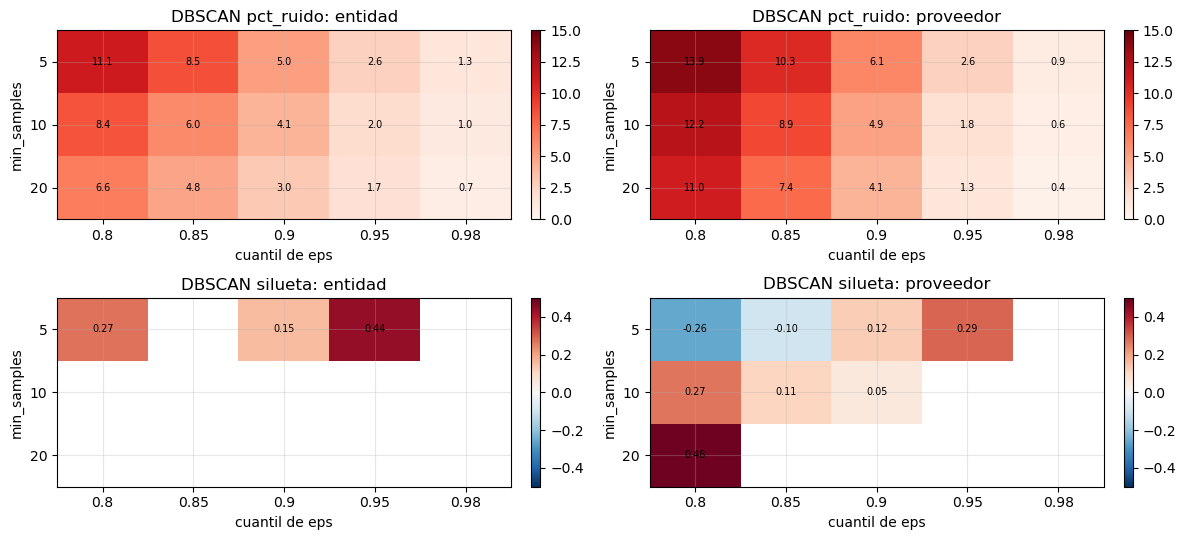

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 5.5))
for i, s in enumerate(datos):
    g = grid_db[grid_db.sujeto == s]
    for j, (met, cmap, lim) in enumerate([("pct_ruido", "Reds", (0, 15)), ("silueta", "RdBu_r", (-0.5, 0.5))]):
        m = g.pivot(index="min_samples", columns="q_eps", values=met)
        im = ax[j, i].imshow(m, cmap=cmap, vmin=lim[0], vmax=lim[1], aspect="auto")
        for (r, c), v in np.ndenumerate(m.to_numpy()):
            ax[j, i].text(c, r, "" if np.isnan(v) else f"{v:.2f}" if met == "silueta" else f"{v:.1f}", ha="center", va="center", fontsize=7)
        ax[j, i].set_xticks(range(m.shape[1])); ax[j, i].set_xticklabels(m.columns); ax[j, i].set_xlabel("cuantil de eps")
        ax[j, i].set_yticks(range(m.shape[0])); ax[j, i].set_yticklabels(m.index); ax[j, i].set_ylabel("min_samples")
        ax[j, i].set_title(f"DBSCAN {met}: {s}")
        fig.colorbar(im, ax=ax[j, i], fraction=0.046, pad=0.04)
mostrar_fig("barrido_dbscan")

- Con `eps` chico (cuantil 0.80) aparecen muchos grupos diminutos y mucho ruido

- Con `min_samples` = 10 o 20, casi todas las configuraciones dan 1 solo grupo

- No hay un rango de `eps` con varios grupos estables

#### a. Ruido máximo aceptable

Qué configuración se elegiría con cada tope de ruido

In [9]:
topes = pd.DataFrame([{"sujeto": s, "ruido_max": r, **({} if (c := elegir(grid_db[grid_db.sujeto == s], r)) is None
                                                      else c[["min_samples", "q_eps", "n_clusters", "pct_ruido", "silueta"]].to_dict())}
                      for s in datos for r in RANGO_RUIDO])
topes

,sujeto,ruido_max,min_samples,q_eps,n_clusters,pct_ruido,silueta
0,entidad,0.05,5,0.95,2,2.6,0.438
1,entidad,0.10,5,0.95,2,2.6,0.438
2,entidad,0.20,5,0.95,2,2.6,0.438
3,proveedor,0.05,5,0.95,6,2.6,0.291
4,proveedor,0.10,5,0.95,6,2.6,0.291
5,proveedor,0.20,20,0.80,2,11.0,0.485


- Con tope de 5% o 10% se elige lo mismo: `min_samples = 5`

- Cuantil 0.95, con 2.6% de ruido (2 grupos en entidades, 6 en proveedores)

- Con 20%, en proveedores se elegiría `min_samples = 20` y cuantil 0.80 

- 2 grupos, 11% de ruido

- Se fija `RUIDO_MAX = 0.10`: la elección es estable entre 5% y 10%

In [10]:
sel_db = {s: elegir(grid_db[grid_db.sujeto == s], RUIDO_MAX) for s in datos}
for s, r in sel_db.items():
    print(s, "→", r[["min_samples", "q_eps", "eps", "n_clusters", "pct_ruido", "silueta"]].to_dict())

entidad → {'min_samples': 5, 'q_eps': 0.95, 'eps': 1.735, 'n_clusters': 2, 'pct_ruido': 2.6, 'silueta': 0.438}
proveedor → {'min_samples': 5, 'q_eps': 0.95, 'eps': 1.181, 'n_clusters': 6, 'pct_ruido': 2.6, 'silueta': 0.291}


---
### **3. HDBSCAN: `min_cluster_size` × `min_samples` × selección**

No `eps`: construye la jerarquía de densidades y se queda con los grupos más estables

In [11]:
grid_h, lab_h = [], {}
for s, (d, X) in datos.items():
    for mcs in RANGO_MCS:
        for ms in RANGO_MS_H:
            for sel in RANGO_SEL:
                h = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=sel).fit(X)
                lab_h[(s, mcs, ms, sel)] = (h.labels_, h.probabilities_)
                dentro = h.labels_ >= 0
                grid_h.append({"sujeto": s, "min_cluster_size": mcs, "min_samples": ms, "seleccion": sel,
                               "n_clusters": len(set(h.labels_) - {-1}), "pct_ruido": round(100 * (~dentro).mean(), 1),
                               "silueta": round(silueta(X, h.labels_), 3),
                               "prob_media": round(float(h.probabilities_[dentro].mean()), 3) if dentro.any() else np.nan})
grid_h = pd.DataFrame(grid_h)
grid_h.pivot_table(index=["seleccion", "min_samples", "min_cluster_size"], columns="sujeto", values=["n_clusters", "pct_ruido", "silueta"])

n_clusters           pct_ruido  \
sujeto                                    entidad proveedor   entidad   
seleccion min_samples min_cluster_size                                  
eom       1           10                        2       205      18.8   
                      25                        3        23      51.0   
                      50                        2        18      84.6   
                      100                       2        15      84.6   
          5           10                        3        41      68.0   
                      25                        2        14      92.1   
                      50                        2         7      92.1   
                      100                       0         6     100.0   
          10          10                        2        25      72.9   
                      25                        2         7      95.8   
                      50                        0         6     100.0   
                      100                       0         6     100.0   
leaf      1           10                       35       294      77.9   
                      25                        6        72      82.5   
                      50                        2        27      84.6   
                      100                       2        17      84.6   
          5           10                        6       127      94.0   
                      25                        2        39      92.1   
                      50                        2        17      92.1   
                      100                       0        14     100.0   
          10          10                        3        62      95.5   
                      25                        2        28      95.8   
                      50                        0        16     100.0   
                      100                       0        13     100.0   

                                                 silueta            
sujeto                                 proveedor entidad proveedor  
seleccion min_samples min_cluster_size                              
eom       1           10                    50.0   0.141     0.071  
                      25                    24.5   0.134    -0.132  
                      50                    51.7   0.281     0.185  
                      100                   54.1   0.281     0.207  
          5           10                    33.3   0.142    -0.113  
                      25                    31.6   0.423    -0.022  
                      50                    27.3   0.423     0.128  
                      100                   27.0     NaN     0.211  
          10          10                    36.4   0.178     0.035  
                      25                    34.1   0.441     0.240  
                      50                    33.9     NaN     0.222  
                      100                   33.9     NaN     0.222  
leaf      1           10                    61.9   0.198     0.292  
                      25                    74.2   0.213     0.268  
                      50                    70.7   0.281     0.191  
                      100                   62.9   0.281     0.210  
          5           10                    81.3   0.146     0.397  
                      25                    80.1   0.423     0.281  
                      50                    63.2   0.423     0.233  
                      100                   60.1     NaN     0.231  
          10          10                    84.6   0.453     0.377  
                      25                    74.1   0.441     0.229  
                      50                    69.0     NaN     0.241  
                      100                   66.8     NaN     0.261

- **Barrido de HDBSCAN:** % de ruido según el tamaño mínimo de grupo

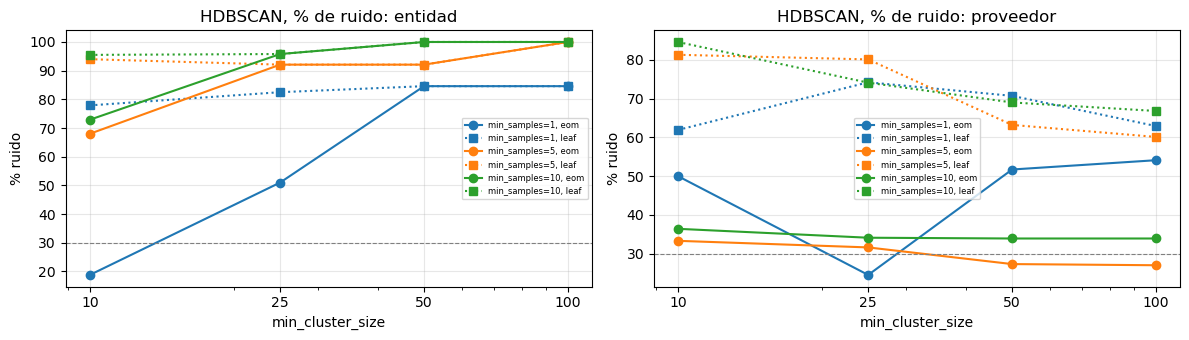

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, s in enumerate(datos):
    for ms, color in zip(RANGO_MS_H, ["tab:blue", "tab:orange", "tab:green"]):
        for sel, estilo in [("eom", "o-"), ("leaf", "s:")]:
            g = grid_h[(grid_h.sujeto == s) & (grid_h.min_samples == ms) & (grid_h.seleccion == sel)]
            ax[i].plot(g.min_cluster_size, g.pct_ruido, estilo, color=color, label=f"min_samples={ms}, {sel}")
    ax[i].axhline(100 * RUIDO_MAX_H, color="grey", ls="--", lw=.8)
    ax[i].set_xscale("log"); ax[i].set_xticks(RANGO_MCS); ax[i].set_xticklabels(RANGO_MCS)
    ax[i].set_title(f"HDBSCAN, % de ruido: {s}"); ax[i].set_xlabel("min_cluster_size"); ax[i].set_ylabel("% ruido"); ax[i].legend(fontsize=6)
mostrar_fig("barrido_hdbscan")

- HDBSCAN marca **mucho ruido** en casi todas las configuraciones: 19-100% en entidades y 24-85% en proveedores

- `leaf` da siempre más ruido que `eom`: se queda con grupos chicos y deja el resto afuera

- Bajar `min_samples` a 1 reduce el ruido: un punto necesita menos vecinos para contar como denso

- La densidad es pareja y **no hay grupos densos bien separados**

#### a. Ruido máximo aceptable (HDBSCAN)

In [13]:
topes_h = pd.DataFrame([{"sujeto": s, "ruido_max": r, **({} if (c := elegir(grid_h[grid_h.sujeto == s], r)) is None
                         else c[["min_cluster_size", "min_samples", "seleccion", "n_clusters", "pct_ruido", "silueta"]].to_dict())}
                        for s in datos for r in RANGO_RUIDO_H])
topes_h

,sujeto,ruido_max,min_cluster_size,min_samples,seleccion,n_clusters,pct_ruido,silueta
0,entidad,0.2,10.0,1.0,eom,2.0,18.8,0.141
1,entidad,0.3,10.0,1.0,eom,2.0,18.8,0.141
2,entidad,0.4,10.0,1.0,eom,2.0,18.8,0.141
3,proveedor,0.2,NaN,NaN,NaN,NaN,NaN,NaN
4,proveedor,0.3,100.0,5.0,eom,6.0,27.0,0.211
5,proveedor,0.4,25.0,10.0,eom,7.0,34.1,0.240


- Con tope de 20%, en proveedores ninguna configuración califica; 

- Con 30% se elige `min_cluster_size = 100`, `min_samples = 5` (6 grupos, 27% de ruido)

- En entidades se elige siempre `min_cluster_size = 10`, `min_samples = 1` (2 grupos, 18.8% de ruido)

- Se fija `RUIDO_MAX_H = 0.30`: menor tope que deja una configuración válida en ambos sujetos

In [14]:
sel_h = {s: elegir(grid_h[grid_h.sujeto == s], RUIDO_MAX_H) for s in datos}
for s in config:
    r, h = sel_db[s], sel_h[s]
    config[s].update(dbscan={"min_samples": int(r.min_samples), "q_eps": float(r.q_eps), "eps": float(r.eps)},
                     hdbscan={"min_cluster_size": int(h.min_cluster_size), "min_samples": int(h.min_samples), "seleccion": h.seleccion},
                     ruido_max=RUIDO_MAX, ruido_max_h=RUIDO_MAX_H)
    print(s, "→", h[["min_cluster_size", "min_samples", "seleccion", "n_clusters", "pct_ruido", "silueta"]].to_dict())
guardar_config(config)

entidad → {'min_cluster_size': 10, 'min_samples': 1, 'seleccion': 'eom', 'n_clusters': 2, 'pct_ruido': 18.8, 'silueta': 0.141}
proveedor → {'min_cluster_size': 100, 'min_samples': 5, 'seleccion': 'eom', 'n_clusters': 6, 'pct_ruido': 27.0, 'silueta': 0.211}


---
### **4. Comparación entre métodos**

- ARI sobre los actores que ningún método marcó como ruido

In [15]:
res, comparacion = {}, []
for s, (d, X) in datos.items():
    r = d[[config[s]["key"], "cluster", "dist_centro"]].rename(columns={"cluster": "kmeans"})
    r["dbscan"] = lab_db[(s, config[s]["dbscan"]["min_samples"], config[s]["dbscan"]["q_eps"])]
    h = config[s]["hdbscan"]
    r["hdbscan"], r["hdbscan_prob"] = lab_h[(s, h["min_cluster_size"], h["min_samples"], h["seleccion"])]
    res[s] = r
    for a, b in [("kmeans", "dbscan"), ("kmeans", "hdbscan"), ("dbscan", "hdbscan")]:
        comparacion.append({"sujeto": s, "par": f"{a} vs {b}", "ari": round(ari(r[a], r[b]), 3)})
comparacion = pd.DataFrame(comparacion)
comparacion.pivot(index="par", columns="sujeto", values="ari")

sujeto,entidad,proveedor
par,,
dbscan vs hdbscan,0.000,0.000
kmeans vs dbscan,0.003,0.007
kmeans vs hdbscan,0.009,0.452


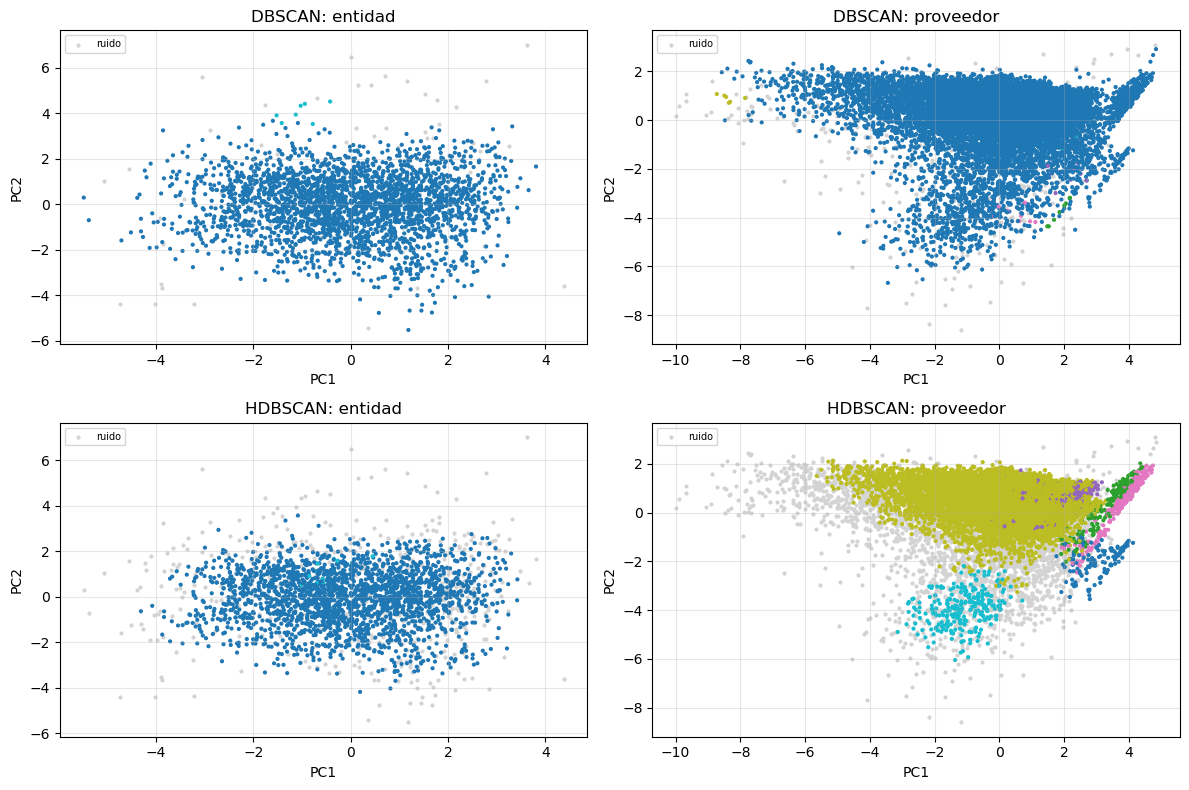

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for i, (s, (d, X)) in enumerate(datos.items()):
    for j, met in enumerate(["dbscan", "hdbscan"]):
        lab = res[s][met].to_numpy()
        ax[j, i].scatter(X[lab == -1, 0], X[lab == -1, 1], c="lightgrey", s=4, label="ruido")
        ax[j, i].scatter(X[lab >= 0, 0], X[lab >= 0, 1], c=lab[lab >= 0], cmap="tab10", s=4)
        ax[j, i].set_title(f"{met.upper()}: {s}"); ax[j, i].set_xlabel("PC1"); ax[j, i].set_ylabel("PC2"); ax[j, i].legend(fontsize=7)
mostrar_fig("densidad_pca")

- **KMeans vs DBSCAN ≈ 0:** DBSCAN deja casi todo en un grupo grande, mientras KMeans parte esa masa en 4

- **KMeans vs HDBSCAN = 0.45 en proveedores:** coinciden parcialmente en los grupos más definidos (obras, sin competencia)

- **DBSCAN vs HDBSCAN = 0:** cada uno separa grupos distintos dentro de la masa

- Los métodos de densidad **no reproducen las tipologías**: KMeans corta un continuo en perfiles

- La densidad sirve sobre todo para detectar **outliers**

---
### **5. Calidad, memoria y tiempo**

- Se repite la configuración elegida sobre muestras de tamaño creciente 

- Solo sobre proveedores, que son los más abundantes

In [17]:
costo = []
d, X = datos["proveedor"]
for n in [m for m in RANGO_N if m <= len(X)] + [len(X)]:
    idx = np.random.RandomState(SEED).choice(len(X), size=n, replace=False)
    c = config["proveedor"]
    _, seg_db, mem_db = medir(lambda: DBSCAN(eps=c["dbscan"]["eps"], min_samples=c["dbscan"]["min_samples"]).fit_predict(X[idx]))
    _, seg_h, mem_h = medir(lambda: HDBSCAN(min_cluster_size=c["hdbscan"]["min_cluster_size"], min_samples=c["hdbscan"]["min_samples"],
                                            cluster_selection_method=c["hdbscan"]["seleccion"]).fit(X[idx]))
    costo.append({"n": n, "seg_dbscan": seg_db, "mb_dbscan": mem_db, "seg_hdbscan": seg_h, "mb_hdbscan": mem_h})
costo = pd.DataFrame(costo).drop_duplicates("n")
costo

,n,seg_dbscan,mb_dbscan,seg_hdbscan,mb_hdbscan
0,1000,0.02,0.3,0.09,0.3
1,2000,0.04,0.7,0.19,0.6
2,5000,0.13,1.7,0.55,1.6
3,10000,0.39,3.5,1.38,3.3
4,13317,0.55,4.7,2.02,4.5


- **Costo:** tiempo y memoria de DBSCAN y HDBSCAN

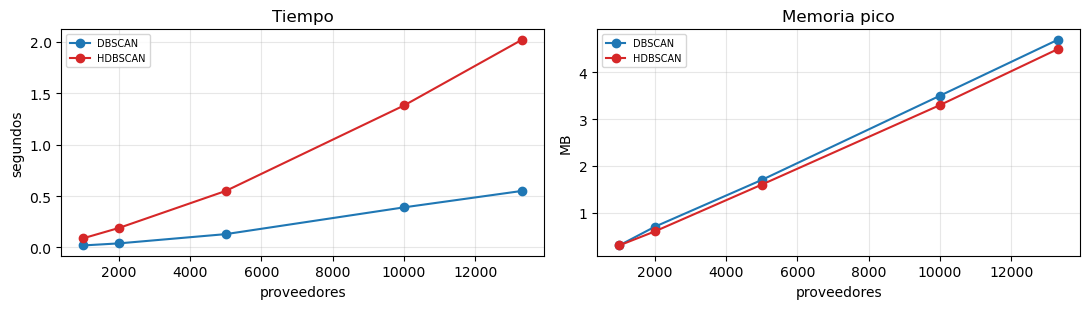

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for met, color in [("dbscan", "tab:blue"), ("hdbscan", "tab:red")]:
    ax[0].plot(costo.n, costo[f"seg_{met}"], "o-", color=color, label=met.upper())
    ax[1].plot(costo.n, costo[f"mb_{met}"], "o-", color=color, label=met.upper())
ax[0].set_title("Tiempo"); ax[0].set_xlabel("proveedores"); ax[0].set_ylabel("segundos"); ax[0].legend(fontsize=7)
ax[1].set_title("Memoria pico"); ax[1].set_xlabel("proveedores"); ax[1].set_ylabel("MB"); ax[1].legend(fontsize=7)
mostrar_fig("costo_densidad")

- Con los 13,317 proveedores, DBSCAN tarda 0.5 s y HDBSCAN 2.0 s, con menos de 5 MB de memoria

- Ambos crecen algo más que linealmente (de 1k a 13k: ×27 y ×22 en tiempo), pero caben de sobra en local

- Por eso se aplican a **todos** los actores, sin muestra

---
### **6. Outliers**

Outlier = ruido de DBSCAN o de HDBSCAN

In [19]:
outliers = []
for s, (d, X) in datos.items():
    r, feats = res[s], config[s]["feats"]
    m = (r.dbscan == -1) | (r.hdbscan == -1)
    o = d.loc[m.to_numpy()].copy()
    o["ruido_dbscan"], o["ruido_hdbscan"] = (r.dbscan[m] == -1).astype(int).to_numpy(), (r.hdbscan[m] == -1).astype(int).to_numpy()
    o["rasgos"] = [rasgos(z, feats) for z in o.z]
    monto = "monto_adjudicado_total" if s == "entidad" else "monto_total"
    outliers.append(o.rename(columns={config[s]["key"]: "clave", monto: "monto"})
                     .assign(sujeto=s)[["sujeto", "clave", "nombre", "n_procesos", "monto", "dist_centro", "ruido_dbscan", "ruido_hdbscan", "rasgos"]])
    r.to_parquet(datos_dir / f"densidad_{s}", index=False)
    print(f"{s}: {m.sum():,} outliers ({100 * m.mean():.1f}%) | DBSCAN {(r.dbscan == -1).sum():,} | HDBSCAN {(r.hdbscan == -1).sum():,}")
outliers = pd.concat(outliers)
outliers.sort_values("dist_centro", ascending=False).groupby("sujeto").head(5)

entidad: 506 outliers (18.8%) | DBSCAN 69 | HDBSCAN 506


proveedor: 3,590 outliers (27.0%) | DBSCAN 345 | HDBSCAN 3,590


,sujeto,clave,nombre,n_procesos,monto,dist_centro,ruido_dbscan,ruido_hdbscan,rasgos
2194,entidad,ENT:205250,AUTORIDAD NACIONAL DE CONTROL DEL MINISTERIO PÚBLICO,5,8.465000e+05,9.702132,1,1,"pct_directa ↑9.6σ, pct_postor_unico ↑7.3σ, log_postores_promedio ↓4.1σ"
1364,entidad,ENT:205170,FORTALECIMIENTO DEL SISTEMA NACIONAL DE VIGILANCIA EN SALUD PÚBLICA,8,1.410137e+05,8.096230,1,1,"pct_postor_unico ↑7.3σ, log_monto_mediano ↓5.8σ, log_postores_promedio ↓4.1σ"
2657,entidad,ENT:202125,UNIDAD EJECUTORA 411 SALUD JULCAN,6,1.347605e+06,8.054921,1,1,"pct_directa ↑9.6σ, pct_postor_unico ↑4.7σ, log_postores_promedio ↓3.7σ"
9489,proveedor,RUC:20501887286,DIAGNOSTICA PERUANA S.A.C.,572,4.083834e+08,7.981661,1,1,"meses_activos ↑6.0σ, log_n_regiones ↑5.1σ, log_n_entidades ↑5.0σ"
1581,proveedor,RUC:20100028698,FERREYROS SOCIEDAD ANÓNIMA,235,5.844381e+08,7.975726,1,1,"meses_activos ↑5.8σ, log_n_entidades ↑5.7σ, log_n_regiones ↑4.6σ"
8392,proveedor,RUC:20101639275,IPESA S.A.C.,209,4.566044e+08,7.718531,1,1,"meses_activos ↑5.8σ, log_n_entidades ↑5.2σ, log_n_regiones ↑4.8σ"
2094,entidad,ENT:86,MUNICIPALIDAD DISTRITAL DE SOLOCO,5,3.371322e+06,7.590630,1,1,"pct_directa ↑9.6σ, pct_obras ↑3.6σ, log_postores_promedio ↓3.5σ"
8312,proveedor,RUC:20100027021,UNIMAQ S.A.,208,2.048934e+08,7.566440,1,1,"meses_activos ↑5.8σ, log_n_entidades ↑5.6σ, log_n_regiones ↑5.0σ"
8552,proveedor,RUC:20260344341,MERCK SHARP & DOHME PERU S.R.L.,3,1.382864e+08,7.528576,1,1,"pct_directa ↑4.8σ, log_monto_mediano ↑4.7σ, log_monto_total ↑3.1σ"
1515,entidad,ENT:204950,PROGRAMA NACIONAL DE INVESTIGACIÓN CIENTÍFICA Y ESTUDIOS AVANZADOS,62,4.207181e+06,6.968740,1,1,"log_monto_mediano ↓8.8σ, pct_postor_unico ↑3.2σ, pct_bienes ↓1.6σ"


- Ruido de DBSCAN o HDBSCAN: 506 entidades (18.8%) y 3,590 proveedores (27.0%)

- Casi todo aportado por HDBSCAN

- DBSCAN solo marca 69 entidades y 345 proveedores: los realmente aislados

#### a. Verificación

In [20]:
for s in config:
    r = pd.read_parquet(datos_dir / f"densidad_{s}")
    assert r[config[s]["key"]].is_unique and len(r) == len(datos[s][1]), s
    print(f"{s}: {len(r):,} actores con etiqueta DBSCAN y HDBSCAN | OK")

entidad: 2,696 actores con etiqueta DBSCAN y HDBSCAN | OK
proveedor: 13,317 actores con etiqueta DBSCAN y HDBSCAN | OK


---
### **7. Escritura de resultados**

In [21]:
escritos = guardar_tablas({"grid_dbscan": grid_db, "topes_ruido": topes.fillna(-1), "grid_hdbscan": grid_h,
                           "topes_ruido_hdbscan": topes_h.fillna(-1),
                           "ari_densidad": comparacion, "costo_densidad": costo, "outliers_densidad": outliers})

Escrito en 02_Clustering/temp/c_densidad/: grid_dbscan, topes_ruido, grid_hdbscan, topes_ruido_hdbscan, ari_densidad, costo_densidad, outliers_densidad


#### a. Verificación

In [22]:
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 5 figuras: barrido_dbscan, barrido_hdbscan, costo_densidad, densidad_pca, k_distancia


---
### **8. Cerrar sesión**

In [23]:
spark.stop()